# Automatic step climbs during cruise

Compare an A320 complete flight and a cruise-only trajectory from Amsterdam (EHAM) to Athens (LGAV) in still air. Both runs minimize fuel and let the optimizer choose the timing and rates of cruise climbs. Each starts at 70,000 kg at the beginning of its own trajectory.

The reported wall time covers the entire `trajectory()` call, including physical validation. Imports, optimizer setup, and plotting are outside the timer.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import opentop
from opentop.plotting import apply_publication_style

apply_publication_style()

## Complete flight

Initial climb and final descent use the usual full-flight constraints. Only cruise has optional step climbs.

In [2]:
optimizer = opentop.CompleteFlight("A320", "EHAM", "LGAV", m0=70_000)
optimizer.setup(nodes=40)

started = perf_counter()
result = optimizer.trajectory(step_climb=True, result_object=True)
elapsed = perf_counter() - started
if not result.success:
    raise RuntimeError(f"Trajectory optimization failed: {result.status}")

flight = result.df
steps = optimizer.step_climb_diagnostics

## Read the selected steps

The cruise mesh provides a limited number of optional climb slots. Each slot ramps up to a sustained vertical rate and then returns to level flight. A slot with zero amplitude stays level. The diagnostics report how many slots were used and the optimized rate in each slot.

In [3]:
def show_steps(result, steps, elapsed):
    lines = [
        f"**Solver status:** {result.status}",
        f"**Trajectory wall time:** {elapsed:.2f} s",
        f"**Selected steps:** {steps['step_count']} of "
        f"{steps['capacity']} available slots",
    ]
    for slot, rate in enumerate(steps["amplitudes_fpm"], start=1):
        lines.append(f"- Slot {slot} sustained rate: {rate:.0f} ft/min")
    display(Markdown("\n\n".join(lines)))


show_steps(result, steps, elapsed)

**Solver status:** Solve_Succeeded

**Trajectory wall time:** 26.54 s

**Selected steps:** 2 of 2 available slots

- Slot 1 sustained rate: 304 ft/min

- Slot 2 sustained rate: 382 ft/min

## Flight profile

The shaded band marks cruise on the full-flight profile. The lower panels show the altitude gain and vertical rate at the cruise nodes.

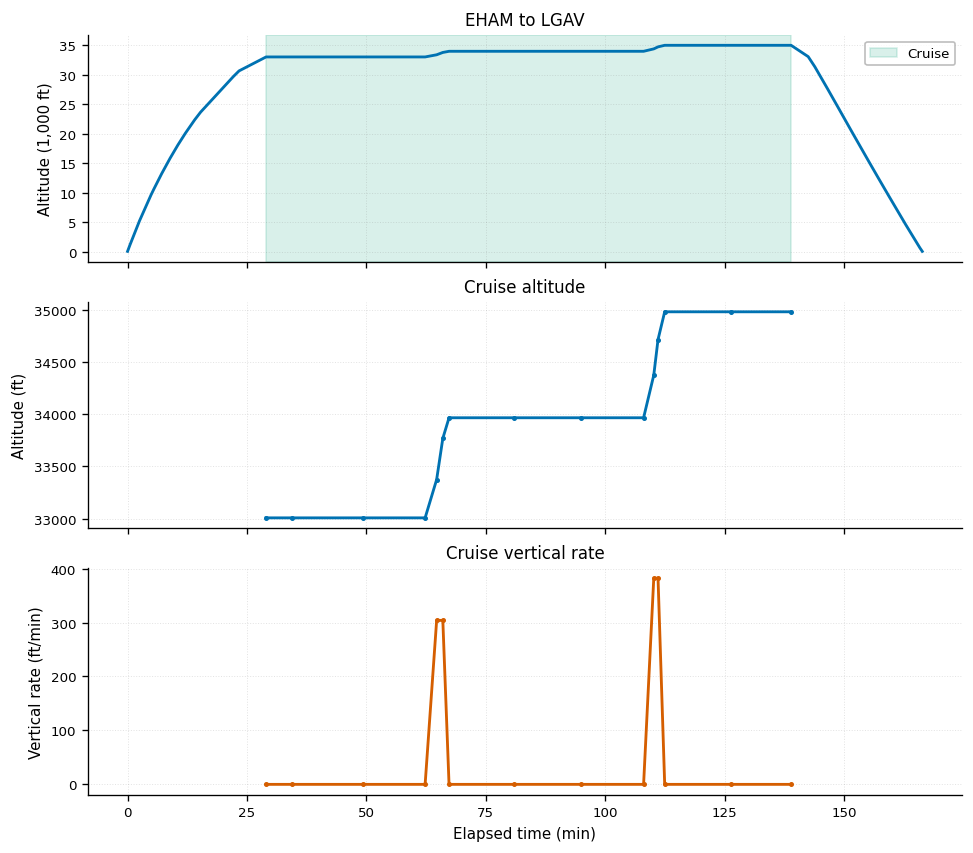

In [4]:
first, last = steps["initialization"]["phase"]
cruise = flight.iloc[first : last + 1]
minutes = flight["ts"] / 60
cruise_minutes = minutes.iloc[first : last + 1]

fig, (profile, altitude, rate) = plt.subplots(
    3, 1, figsize=(8, 7), sharex=True, layout="constrained"
)

profile.plot(minutes, flight["altitude"] / 1_000)
profile.axvspan(
    cruise_minutes.iloc[0],
    cruise_minutes.iloc[-1],
    color="C2",
    alpha=0.15,
    label="Cruise",
)
profile.set(title="EHAM to LGAV", ylabel="Altitude (1,000 ft)")
profile.legend()

altitude.plot(cruise_minutes, cruise["altitude"], ".-")
altitude.set(title="Cruise altitude", ylabel="Altitude (ft)")
altitude.ticklabel_format(axis="y", style="plain", useOffset=False)

rate.plot(cruise_minutes, cruise["vertical_rate"], ".-", color="C1")
rate.set(title="Cruise vertical rate", ylabel="Vertical rate (ft/min)")

for axis in (profile, altitude, rate):
    axis.grid(True)
rate.set_xlabel("Elapsed time (min)")
plt.show()

## Cruise only

Optimize the same route entirely at cruise altitude with 30 intervals. Here 70,000 kg is the mass at cruise entry. This is a separate optimization, so its cruise profile can differ from the cruise segment of the complete flight.

In [5]:
cruise_optimizer = opentop.Cruise("A320", "EHAM", "LGAV", m0=70_000)
cruise_optimizer.setup(nodes=30)

started = perf_counter()
cruise_result = cruise_optimizer.trajectory(step_climb=True, result_object=True)
cruise_elapsed = perf_counter() - started
if not cruise_result.success:
    raise RuntimeError(f"Cruise optimization failed: {cruise_result.status}")

show_steps(cruise_result, cruise_optimizer.step_climb_diagnostics, cruise_elapsed)

**Solver status:** Solve_Succeeded

**Trajectory wall time:** 23.78 s

**Selected steps:** 3 of 3 available slots

- Slot 1 sustained rate: 125 ft/min

- Slot 2 sustained rate: 117 ft/min

- Slot 3 sustained rate: 236 ft/min

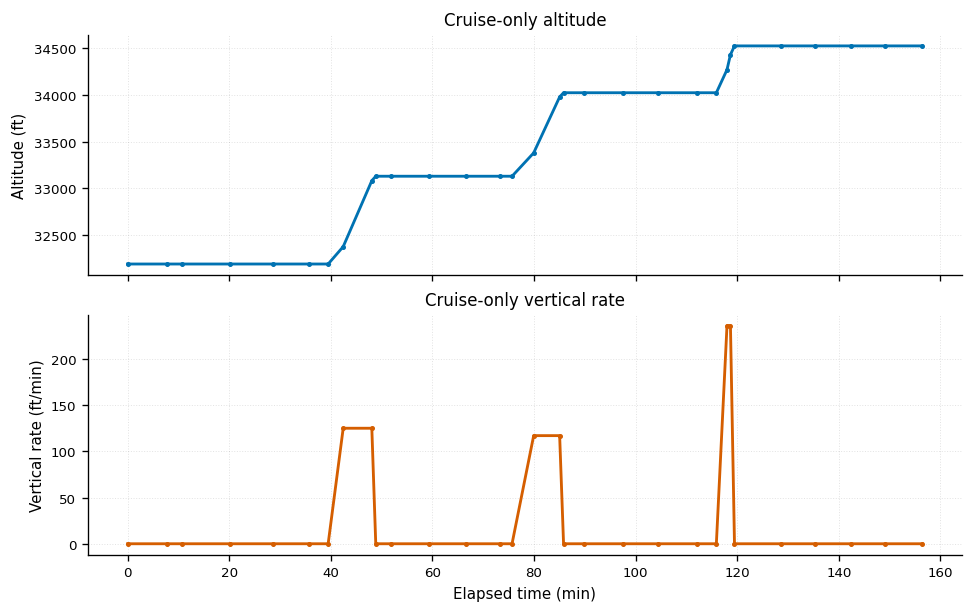

In [6]:
cruise_only = cruise_result.df
minutes = cruise_only["ts"] / 60

fig, (altitude, rate) = plt.subplots(
    2, 1, figsize=(8, 5), sharex=True, layout="constrained"
)
altitude.plot(minutes, cruise_only["altitude"], ".-")
altitude.set(title="Cruise-only altitude", ylabel="Altitude (ft)")
altitude.ticklabel_format(axis="y", style="plain", useOffset=False)

rate.plot(minutes, cruise_only["vertical_rate"], ".-", color="C1")
rate.set(title="Cruise-only vertical rate", ylabel="Vertical rate (ft/min)")
for axis in (altitude, rate):
    axis.grid(True)
rate.set_xlabel("Elapsed time (min)")
plt.show()